# Part 2 · Notebook 5: Filling NDVI gaps with radar

**Goal:** fill the holes that clouds leave in NDVI curves, and find out when Sentinel-1 radar really helps,
up to the real-life case: a model trained on last season, applied to this one.
[Notebook 4](04_ndvi_data.ipynb) showed how large the holes are and how radar follows NDVI.

**How the test works.** Clear NDVI observations are hidden, the methods fill them, and the true values score
them. Errors are mean absolute errors (MAE) in NDVI units, with intervals that resample whole plots. Design
choices are made on validation plots or by cross-validation; test plots are only used to report.

**Part A: within one season (2024–25).** The plots are split 60 / 20 / 20 into training, validation and
test, and about 25 % of each plot's observations are hidden (one 30-day block plus single steps).

1. How far does a straight line across the gap go?
2. First attempt: models with radar.
3. Is the gain really radar?
4. Why not, and for which crop?
5. A first fix: radar per crop.
6. Settling it with cross-validation.
7. Following a field in real time.

**Part B: real life.** Models trained on 2023–24, applied to the 2024–25 plots.

8. The next season, after the season.
9. The next season, in real time.
10. The next season, with real cloud patterns.
11. From the lab to real life.

**Part C: what failed, and the fix.** Why the last-season models did worse than a straight line, and what
changes when the date is removed.

12. Why the last-season models failed.
13. The fix: models without the date.
14. From the lab to real life, after the fix.

*The six GRU trainings run on the GPU when there is one (about 7 minutes each) and are cached in
`data/interim/part2/`; later runs reload them.*

In [1]:
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from xgboost import XGBRegressor

from sentinel_agri.config import FIGURES_DIR, INTERIM_DIR, ROOT, SEASONS
from sentinel_agri.gapfill import (
    GAP_LABELS,
    NO_RADAR_FEATURES,
    PAST_NO_RADAR_FEATURES,
    PAST_RADAR_FEATURES,
    STEP_DAYS,
    TABULAR_FEATURES,
    without_date,
    bootstrap_mae,
    build_grid,
    despike,
    errors,
    linear_fill,
    make_masks,
    paired_difference,
    savgol_fill,
    tabular,
)
from sentinel_agri.gru import GapFillGRU, predict_gru, train_gru
from sentinel_agri.parcels import select_parcels
from sentinel_agri.timeseries import s1_backscatter, s2_ndvi

warnings.filterwarnings("ignore", message=".*torch.jit.script.*")
sns.set_theme(style="whitegrid", context="notebook")
SEED = 0
MONTHS = mdates.DateFormatter("%b")
CROPS = ["Winter rapeseed", "Winter wheat"]
STYLE = {  # colour and line style; the no-radar version of a model is dashed
    "Linear interpolation": ("#9e9e9e", "-"), "Savitzky-Golay": ("#6baed6", "-"),
    "XGBoost, no radar": ("#fdae6b", "--"), "XGBoost": ("#e6550d", "-"),
    "GRU, no radar": ("#a1d99b", "--"), "GRU": ("#31a354", "-"),
    "XGBoost per crop": ("#756bb1", "-"),
}  # fmt: skip

grids = {}
for season in SEASONS:
    parcels = select_parcels(season)
    g = build_grid(s2_ndvi(parcels, season), s1_backscatter(parcels, season), parcels, season)  # cached by notebook 4
    raw = g.ndvi.copy()
    g.ndvi, removed = despike(raw)  # clouds the mask missed: one bad date between two good ones
    grids[season] = g
    print(f"{season}: {len(g.parcel_ids)} plots, {removed.sum()} cloud spikes removed of {(~np.isnan(raw)).sum()} observations")
# 2024 is a leap year: 2023-24 has one more 5-day step (31 August, after harvest). Both seasons are
# trimmed to the same length, so that cloud patterns can be moved from one season to the other.
n_steps = min(g.ndvi.shape[1] for g in grids.values())
for g in grids.values():
    g.dates, g.ndvi, g.s1 = g.dates[:n_steps], g.ndvi[:, :n_steps], g.s1[:, :n_steps]
grid, grid_prev = grids["2024-25"], grids["2023-24"]


def gaps_for(g, rows, seed):
    hidden = np.zeros_like(g.observed)
    hidden[rows] = make_masks(g.observed[rows], seed=seed)
    return hidden


rng = np.random.default_rng(SEED)
train, val, test = [], [], []
for crop in CROPS:  # 2024-25 split by plot, stratified by crop
    rows = rng.permutation(np.flatnonzero(grid.crops == crop))
    n_train, n_val = int(0.6 * len(rows)), int(0.2 * len(rows))
    train += list(rows[:n_train]); val += list(rows[n_train:n_train + n_val]); test += list(rows[n_train + n_val:])
train, val, test = map(np.array, (train, val, test))
val_hidden, test_hidden = gaps_for(grid, val, seed=1), gaps_for(grid, test, seed=2)
test_visible = grid.observed & ~test_hidden
row_of = {pid: i for i, pid in enumerate(grid.parcel_ids)}
print(f"2024-25: {len(train)} training, {len(val)} validation, {len(test)} test plots | test: {test_hidden.sum()} hidden values")

2023-24: 1184 plots, 14 cloud spikes removed of 20850 observations
2024-25: 1254 plots, 59 cloud spikes removed of 44073 observations
2024-25: 752 training, 250 validation, 252 test plots | test: 2203 hidden values


In [2]:
def fit_xgb(features, train_df, val_df):
    """XGBoost on absolute error; the number of trees is chosen on `val_df`."""
    model = XGBRegressor(
        n_estimators=3000, learning_rate=0.03, max_depth=5, subsample=0.8, colsample_bytree=0.8,
        objective="reg:absoluteerror", early_stopping_rounds=100, random_state=SEED,
    )  # fmt: skip
    model.fit(train_df[features], train_df["target"], eval_set=[(val_df[features], val_df["target"])], verbose=False)
    return model


def per_crop(features, train_df, val_df, test_df):
    """One model per crop (as in the cross-validation); absolute errors on `test_df`."""
    out = []
    for crop in CROPS:
        tr, va, te = (t[t["crop"] == crop] for t in (train_df, val_df, test_df))
        f = [x for x in features if x != "rapeseed"]  # constant within one crop
        out.append(pd.Series(np.abs(fit_xgb(f, tr, va).predict(te[f]) - te["target"].to_numpy()), index=te.index))
    return pd.concat(out).reindex(test_df.index)


def to_grid(table, values):
    out = np.full(grid.ndvi.shape, np.nan)
    out[[row_of[pid] for pid in table["parcel_id"]], table["step"].to_numpy()] = values
    return out


GRU_CACHE = INTERIM_DIR / "part2"  # delete gru_*.pt there after changing the data or the GRU
GRU_CACHE.mkdir(parents=True, exist_ok=True)


def gru_model(tag, g, fit_rows, stop_rows, stop_hidden, use_radar, use_date=True):
    """Train the GRU once and cache it; returns the model and its input scaling."""
    name = f"gru_{tag}_{'radar' if use_radar else 'no_radar'}{'' if use_date else '_no_date'}_seed{SEED}.pt"
    path = GRU_CACHE / name
    if not path.exists():
        model, scaling, history = train_gru(g, fit_rows, stop_rows, stop_hidden, epochs=1200, seed=SEED, log_every=400, use_radar=use_radar, use_date=use_date)
        torch.save({"state": model.state_dict(), "scaling": scaling, "use_radar": use_radar, "use_date": use_date, "val_mae": history["val_mae"].to_numpy()}, path)
    saved = torch.load(path, weights_only=False)
    model = GapFillGRU(n_inputs=9)
    model.load_state_dict(saved["state"])
    model.use_radar, model.use_date = saved["use_radar"], saved.get("use_date", True)
    print(f"GRU {tag}, {'with' if use_radar else 'without'} radar{'' if use_date else ', no date'}: best validation MAE {saved['val_mae'].min():.4f}")
    return model, saved["scaling"]


def mae_bars(values, title, intervals=None, ax=None):
    """Horizontal bars, one per method, first on top; optional 95 % intervals."""
    values = pd.Series(values)
    ax = ax or plt.subplots(figsize=(8, 0.5 * len(values) + 1.2))[1]
    y = np.arange(len(values))[::-1]
    colors = [STYLE.get(name.split(" (")[0], ("#4a7ab5", "-"))[0] for name in values.index]  # "XGBoost (last season)" -> XGBoost
    xerr = None
    if intervals is not None:
        intervals = np.array(intervals)
        xerr = [values.to_numpy() - intervals[:, 0], intervals[:, 1] - values.to_numpy()]
    ax.barh(y, values, color=colors, xerr=xerr, capsize=3)
    right = values.to_numpy() if intervals is None else intervals[:, 1]
    for yi, v, r in zip(y, values, right):
        ax.text(r, yi, f"  {v:.4f}", va="center", fontsize=9)
    ax.set_yticks(y, values.index)
    ax.set_xlim(0, right.max() * 1.25)
    ax.set_xlabel("MAE (NDVI)")
    ax.set_title(title)
    return ax


def effect_plot(table, title, ax=None):
    """Paired differences with their 95 % interval. Green: clearly better, red: clearly worse, grey: noise."""
    ax = ax or plt.subplots(figsize=(9, 0.55 * len(table) + 1.3))[1]
    y = np.arange(len(table))[::-1]
    for yi, (_, row) in zip(y, table.iterrows()):
        color = "#31a354" if row["high"] < 0 else "#de2d26" if row["low"] > 0 else "#636363"
        ax.errorbar(row["difference"], yi, xerr=[[row["difference"] - row["low"]], [row["high"] - row["difference"]]],
                    fmt="o", color=color, capsize=4, lw=2, ms=7)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_yticks(y, table.index)
    ax.set_xlabel("Difference in MAE (NDVI); negative = the first is better")
    ax.set_title(title)
    return ax

# Part A: within one season (2024–25)

## 1. How far does a straight line go?

The simplest way to fill a hole: a straight line between the clear values on either side. A Savitzky-Golay
filter, the classic way to smooth NDVI series, is added for comparison.

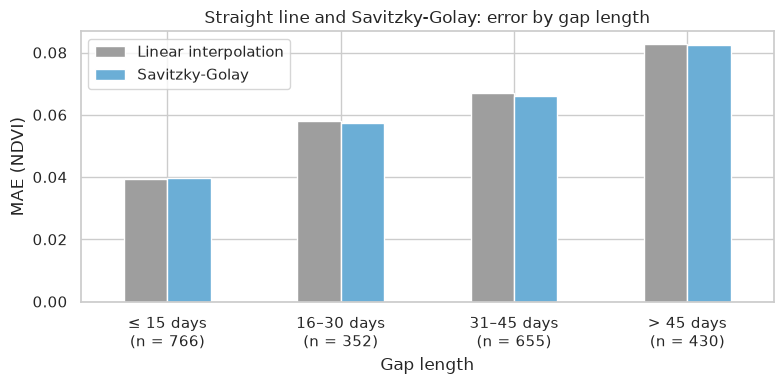

In [3]:
predictions = {
    "Linear interpolation": linear_fill(grid.ndvi, test_visible),
    "Savitzky-Golay": savgol_fill(grid.ndvi, test_visible),
}
baseline_errors = errors(grid, test, test_hidden, predictions)
by_gap = baseline_errors.groupby("gap", observed=True)[list(predictions)].mean().reindex(GAP_LABELS)
counts = baseline_errors["gap"].value_counts().reindex(GAP_LABELS)
ax = by_gap.plot.bar(figsize=(8, 4), rot=0, color=[STYLE[m][0] for m in by_gap.columns])
ax.set_xticklabels([f"{g}\n(n = {n})" for g, n in counts.items()])
ax.set_xlabel("Gap length")
ax.set_ylabel("MAE (NDVI)")
ax.set_title("Straight line and Savitzky-Golay: error by gap length")
plt.tight_layout()

**What it shows**

- The straight line's error grows with the gap: 0.039 for gaps up to 15 days, 0.083 beyond 45 days
  (0.059 overall).
- Savitzky-Golay does no better. Smoothing helps noisy series, but these values are already cleaned, and
  inside a gap it only smooths the straight line.

## 2. First attempt: models with radar

- **XGBoost** gets one row per hidden value: the clear NDVI before and after the gap and their distances,
  the straight line itself, the day of the year, the crop, and the radar (VV, VH, VH/VV) at that step and
  its change since the clear dates.
- **A GRU** (a recurrent neural network) reads each plot's whole season step by step: radar, day of the
  year, the visible NDVI, the crop. It is trained on new random gaps at every epoch.

GRU 2024-25, with radar: best validation MAE 0.0284
GRU 2024-25, without radar: best validation MAE 0.0313


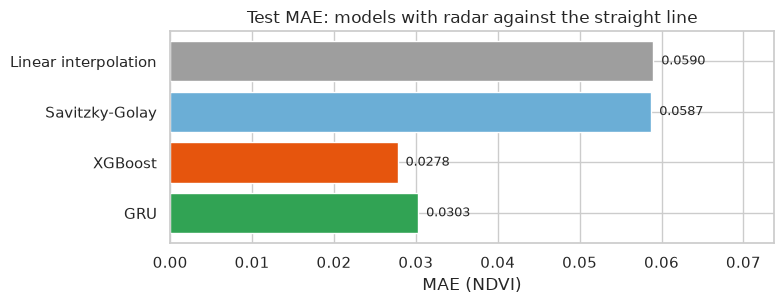

In [4]:
train_table = pd.concat([tabular(grid, train, gaps_for(grid, train, seed=100 + k)) for k in range(5)], ignore_index=True)
val_table = tabular(grid, val, val_hidden)
test_table = tabular(grid, test, test_hidden)
xgb_models = {"XGBoost": fit_xgb(TABULAR_FEATURES, train_table, val_table)}
predictions["XGBoost"] = to_grid(test_table, xgb_models["XGBoost"].predict(test_table[TABULAR_FEATURES]))
gru_same = {r: gru_model("2024-25", grid, train, val, val_hidden, use_radar=r) for r in (True, False)}
predictions["GRU"] = predict_gru(gru_same[True][0], grid, test_hidden, gru_same[True][1])

step2 = errors(grid, test, test_hidden, predictions)
mae_bars(step2[["Linear interpolation", "Savitzky-Golay", "XGBoost", "GRU"]].mean(), "Test MAE: models with radar against the straight line")
plt.tight_layout()

**What it shows**

- Both models halve the error of the straight line: 0.028 for XGBoost and 0.030 for the GRU, against 0.059.
- It is too early to credit radar: the models also got the date, the crop and the clear values around the gap.

## 3. Is the gain really radar?

A model can beat the straight line without radar: it can learn each crop's calendar (when NDVI rises,
peaks and falls) and use the clear values around the gap. Both models are trained again with the same
inputs, minus the radar.

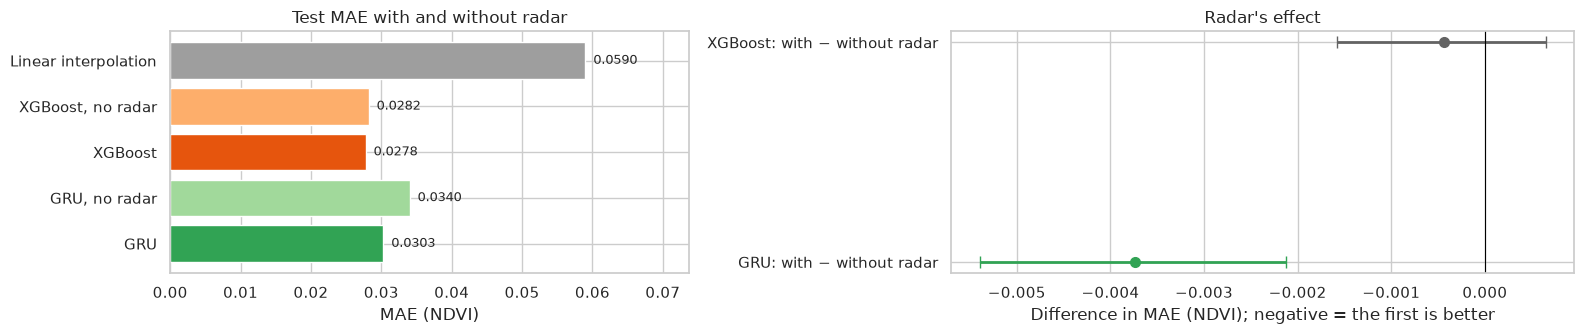

In [5]:
xgb_models["XGBoost, no radar"] = fit_xgb(NO_RADAR_FEATURES, train_table, val_table)
predictions["XGBoost, no radar"] = to_grid(test_table, xgb_models["XGBoost, no radar"].predict(test_table[NO_RADAR_FEATURES]))
predictions["GRU, no radar"] = predict_gru(gru_same[False][0], grid, test_hidden, gru_same[False][1])

step3 = errors(grid, test, test_hidden, predictions)
fig, axes = plt.subplots(1, 2, figsize=(16, 3.5), gridspec_kw={"width_ratios": [1, 1.2]})
mae_bars(step3[["Linear interpolation", "XGBoost, no radar", "XGBoost", "GRU, no radar", "GRU"]].mean(), "Test MAE with and without radar", ax=axes[0])
effect_plot(pd.DataFrame({
    "XGBoost: with − without radar": paired_difference(step3, "XGBoost", "XGBoost, no radar"),
    "GRU: with − without radar": paired_difference(step3, "GRU", "GRU, no radar"),
}).T, "Radar's effect", ax=axes[1])
plt.tight_layout()

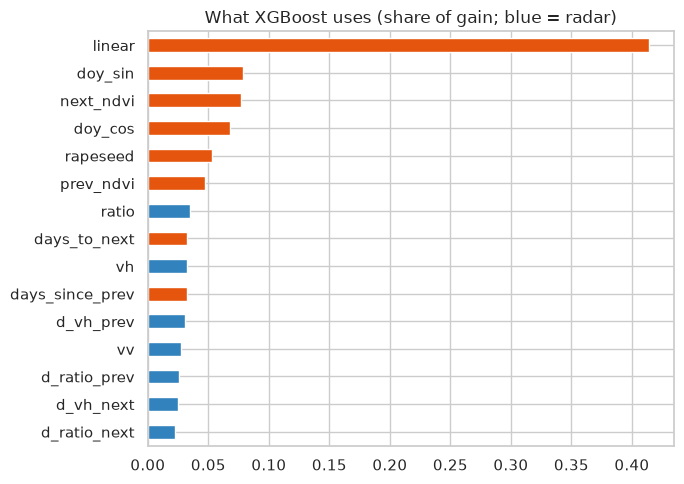

In [6]:
importance = pd.Series(xgb_models["XGBoost"].get_booster().get_score(importance_type="gain")).reindex(TABULAR_FEATURES).fillna(0)
importance = (importance / importance.sum()).sort_values()
colors = ["#3182bd" if f not in NO_RADAR_FEATURES else "#e6550d" for f in importance.index]
importance.plot.barh(figsize=(7, 5), color=colors, title="What XGBoost uses (share of gain; blue = radar)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "part2_xgb_importance.png", dpi=130)

**What it shows**

- Without radar, XGBoost loses almost nothing (0.0282 against 0.0278, within noise). The GRU gains 0.004 from
  radar.
- XGBoost leans on the straight line (41 % of its gain), then on the **day of the year** (15 % for its two
  features) and the clear values around the gap. Each radar feature brings 2 to 4 %.
- So most of the gain does not come from radar. The weight of the date will matter in section 12.

## 4. Why not, and for which crop?

**Presentation**, checked on the validation plots. Radar varies from day to day (rain, soil moisture). Two
alternatives: radar smoothed over 15 days, and how far radar departs from its own straight line across the
gap.

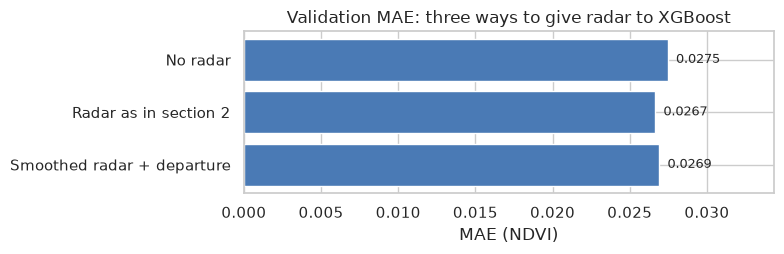

In [7]:
smooth = np.stack([pd.DataFrame(grid.s1[p]).rolling(3, center=True, min_periods=1).mean().to_numpy() for p in range(len(grid.parcel_ids))])


def with_smoothed_radar(table):
    p = table["parcel_id"].map(row_of).to_numpy()
    t = table["step"].to_numpy()
    tp = t - table["days_since_prev"].to_numpy() // STEP_DAYS
    tn = t + table["days_to_next"].to_numpy() // STEP_DAYS
    w = (t - tp) / (tn - tp)
    table = table.copy()
    for v, name in enumerate(["vv", "vh", "ratio"]):
        table[f"smooth_{name}"] = smooth[p, t, v]
        table[f"departure_{name}"] = smooth[p, t, v] - (smooth[p, tp, v] + (smooth[p, tn, v] - smooth[p, tp, v]) * w)
    return table


SMOOTH_FEATURES = NO_RADAR_FEATURES + [f"{k}_{v}" for k in ("smooth", "departure") for v in ("vv", "vh", "ratio")]
train_s, val_s = with_smoothed_radar(train_table), with_smoothed_radar(val_table)
presentation = {}
for name, features in [("No radar", NO_RADAR_FEATURES), ("Radar as in section 2", TABULAR_FEATURES), ("Smoothed radar + departure", SMOOTH_FEATURES)]:
    presentation[name] = np.abs(fit_xgb(features, train_s, val_s).predict(val_s[features]) - val_s["target"]).mean()
mae_bars(presentation, "Validation MAE: three ways to give radar to XGBoost")
plt.tight_layout()

**What it shows**

- Smoothed radar does no better (0.0269 against 0.0267): the way radar is presented is not the problem.

**Crop.** The test errors of sections 2 and 3, split by crop:

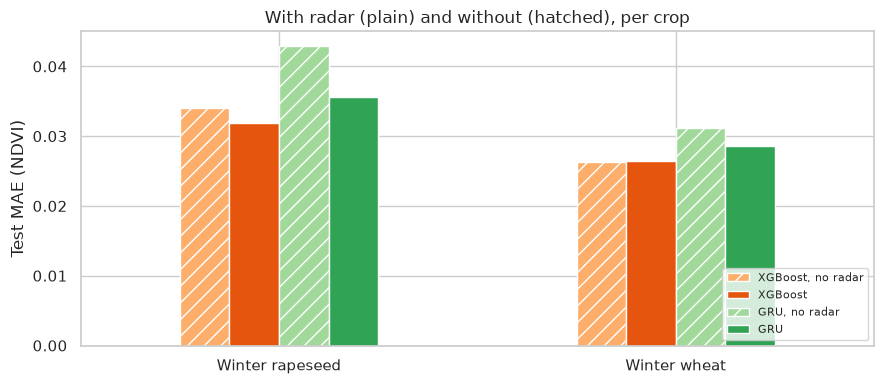

In [8]:
by_crop = step3.groupby("crop")[["XGBoost, no radar", "XGBoost", "GRU, no radar", "GRU"]].mean()
ax = by_crop.plot.bar(figsize=(9, 4), rot=0, color=[STYLE[m][0] for m in by_crop.columns])
for container, model in zip(ax.containers, by_crop.columns):
    if "no radar" in model:
        for bar in container:
            bar.set_hatch("//")
ax.set_ylabel("Test MAE (NDVI)")
ax.set_xlabel("")
ax.set_title("With radar (plain) and without (hatched), per crop")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()

**What it shows**

- Rapeseed is harder to fill, and that is where radar helps: 0.034 to 0.032 for XGBoost, 0.043 to 0.036 for
  the GRU. For wheat, XGBoost does the same with or without radar.
- This matches notebook 4: rapeseed's NDVI follows its VH, while wheat's link to radar is weaker.

## 5. A first fix: radar per crop

One XGBoost model per crop, trained with and without radar; the version with the lower validation error is
kept (**XGBoost per crop**). The chart shows radar's effect per crop on the validation plots, which decide,
and on the test plots, which check.

Kept on validation: {'Winter rapeseed': 'with radar', 'Winter wheat': 'with radar'}


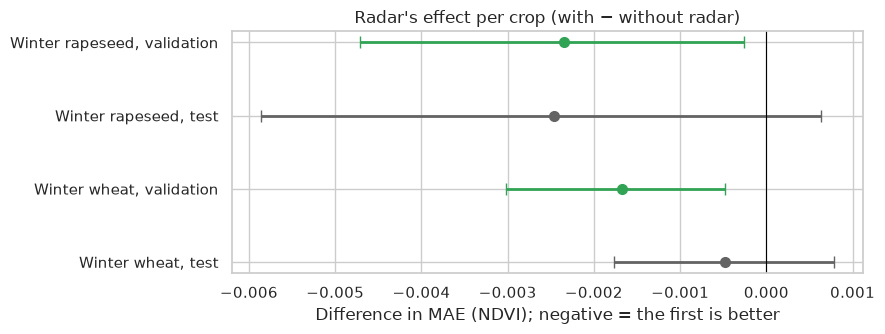

In [9]:
effects, selection, per_crop_pred = {}, {}, np.full(grid.ndvi.shape, np.nan)
for crop in CROPS:
    tr, va, te = (t[t["crop"] == crop] for t in (train_table, val_table, test_table))
    variants = {}
    for label, features in [("without radar", NO_RADAR_FEATURES), ("with radar", TABULAR_FEATURES)]:
        features = [f for f in features if f != "rapeseed"]
        model = fit_xgb(features, tr, va)
        variants[label] = {
            "model": model, "features": features,
            "val": va[["parcel_id"]].assign(err=np.abs(model.predict(va[features]) - va["target"])),
            "test": te[["parcel_id"]].assign(err=np.abs(model.predict(te[features]) - te["target"])),
        }  # fmt: skip
    for split in ("val", "test"):
        pair = variants["with radar"][split].assign(base=variants["without radar"][split]["err"])
        effects[f"{crop}, {'validation' if split == 'val' else 'test'}"] = paired_difference(pair, "err", "base")
    kept = min(variants, key=lambda k: variants[k]["val"]["err"].mean())
    selection[crop] = kept
    crop_pred = to_grid(te, variants[kept]["model"].predict(te[variants[kept]["features"]]))
    per_crop_pred = np.where(np.isnan(crop_pred), per_crop_pred, crop_pred)
predictions["XGBoost per crop"] = per_crop_pred
print("Kept on validation:", selection)
effect_plot(pd.DataFrame(effects).T, "Radar's effect per crop (with − without radar)")
plt.tight_layout()

**What it shows**

- On the validation plots, radar helps both crops, so both keep it.
- On the test plots, the direction is the same but the intervals cross zero: 250 plots are too few to see an
  effect of 0.001 to 0.002.

## 6. Settling it with cross-validation

The training and validation plots are split into 5 groups; each group in turn is held out, one model per
crop is trained on the other four, with and without radar, and radar's effect is measured on the held-out
plots. The test plots stay untouched.

Radar's effect per fold: [-0.0008, -0.0011, -0.0016, -0.0017, -0.003]


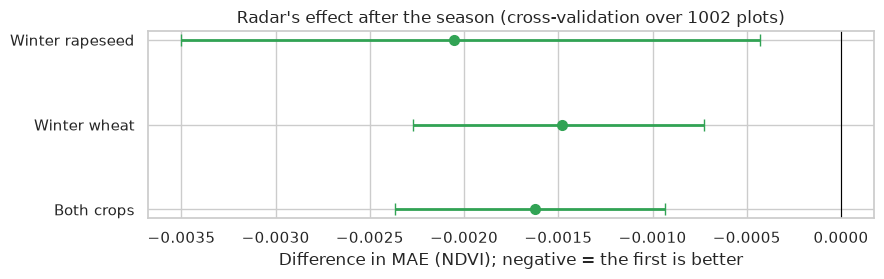

In [10]:
pool = np.concatenate([train, val])
folds = np.array_split(np.random.default_rng(1).permutation(pool), 5)


def cross_validate(features_without, features_with):
    records = []
    for k, held in enumerate(folds):
        fit_rows = np.setdiff1d(pool, held)
        fit_table = pd.concat([tabular(grid, fit_rows, gaps_for(grid, fit_rows, 100 + j)) for j in range(3)], ignore_index=True)
        held_table = tabular(grid, held, gaps_for(grid, held, 50 + k))
        stop = np.isin(fit_table["parcel_id"], np.random.default_rng(k).choice(fit_table["parcel_id"].unique(), len(fit_rows) // 8, replace=False))
        record = held_table[["parcel_id", "crop", "days_since_prev"]].assign(fold=k)
        for label, features in [("without", features_without), ("with", features_with)]:
            record[label] = per_crop(features, fit_table[~stop], fit_table[stop], held_table)
        records.append(record)
    return pd.concat(records, ignore_index=True)


cv_offline = cross_validate(NO_RADAR_FEATURES, TABULAR_FEATURES)
table = pd.DataFrame({crop: paired_difference(cv_offline[cv_offline["crop"] == crop], "with", "without") for crop in CROPS}).T
table.loc["Both crops"] = paired_difference(cv_offline, "with", "without")
print("Radar's effect per fold:", cv_offline.groupby("fold").apply(lambda d: round(d["with"].mean() - d["without"].mean(), 4), include_groups=False).tolist())
effect_plot(table, f"Radar's effect after the season (cross-validation over {len(pool)} plots)")
plt.tight_layout()

**What it shows**

- Over 1,002 plots, radar's effect is clear for both crops (−0.0021 for rapeseed, −0.0015 for wheat) and holds
  in all five folds.
- Real, but small: about 5 % of the error.

## 7. Following a field in real time

The models above know the clear value **after** the gap. Someone following a field week by week only knows
the past. The same cross-validation with past information only (the last clear NDVI and its age, the day of
the year, the crop; for the radar version, the current radar and its change since the last clear date),
then a check on the test plots.

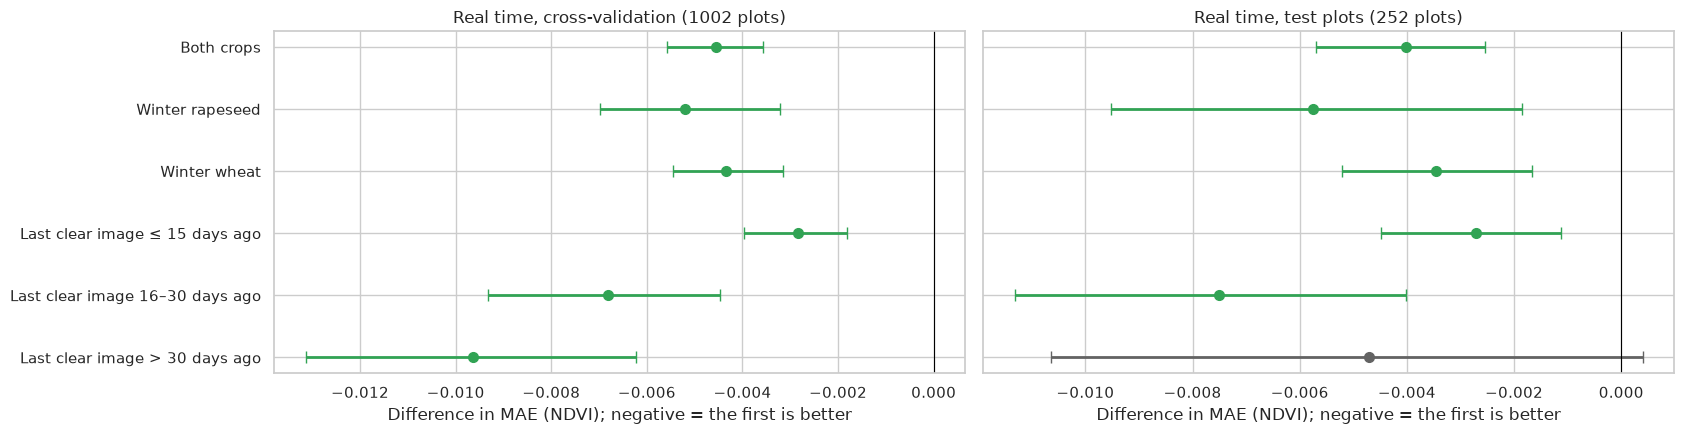

In [11]:
PAST_NO_RADAR, PAST_RADAR = PAST_NO_RADAR_FEATURES, PAST_RADAR_FEATURES  # src/sentinel_agri/gapfill.py
SINCE_BINS, SINCE_LABELS = [0, 15, 30, 1000], ["≤ 15 days", "16–30 days", "> 30 days"]


def realtime_table(df, without="without", with_="with"):
    df = df.assign(since=pd.cut(df["days_since_prev"], SINCE_BINS, labels=SINCE_LABELS))
    table = pd.DataFrame({"Both crops": paired_difference(df, with_, without)}).T
    for crop in CROPS:
        table.loc[crop] = paired_difference(df[df["crop"] == crop], with_, without)
    for since in SINCE_LABELS:
        table.loc[f"Last clear image {since} ago"] = paired_difference(df[df["since"] == since], with_, without)
    return table


cv_realtime = cross_validate(PAST_NO_RADAR, PAST_RADAR)
realtime_test = test_table[["parcel_id", "crop", "days_since_prev"]].copy()
realtime_test["without"] = per_crop(PAST_NO_RADAR, train_table, val_table, test_table)
realtime_test["with"] = per_crop(PAST_RADAR, train_table, val_table, test_table)
fig, axes = plt.subplots(1, 2, figsize=(17, 4.5), sharey=True)
effect_plot(realtime_table(cv_realtime), f"Real time, cross-validation ({len(pool)} plots)", ax=axes[0])
effect_plot(realtime_table(realtime_test), f"Real time, test plots ({len(test)} plots)", ax=axes[1])
plt.tight_layout()
plt.savefig(FIGURES_DIR / "part2_realtime_same_season.png", dpi=130)

**What it shows**

- In real time, radar helps more (−0.0045), and more the longer the last clear image is ago: −0.003 under 15
  days, −0.010 beyond 30 days in cross-validation.
- The test plots agree, except beyond 30 days, where they are too few.
- Part A's verdict: within one season, learned models halve the error, and radar adds a little after the
  season and more in real time. Part B checks whether this survives a new season.

# Part B: real life, a model trained on last season

From here on, models are trained on **2023–24** only (85 % of its plots for training, 15 % to stop training)
and applied to **2024–25**, a season they have never seen, on fields that are partly new. This is how a
gap-filling service would run.

## 8. The next season, after the season

The 2024–25 test plots and gaps of part A, filled by models trained on 2023–24, compared with the
same-season models of part A.

GRU 2023-24, with radar: best validation MAE 0.0451
GRU 2023-24, without radar: best validation MAE 0.0503


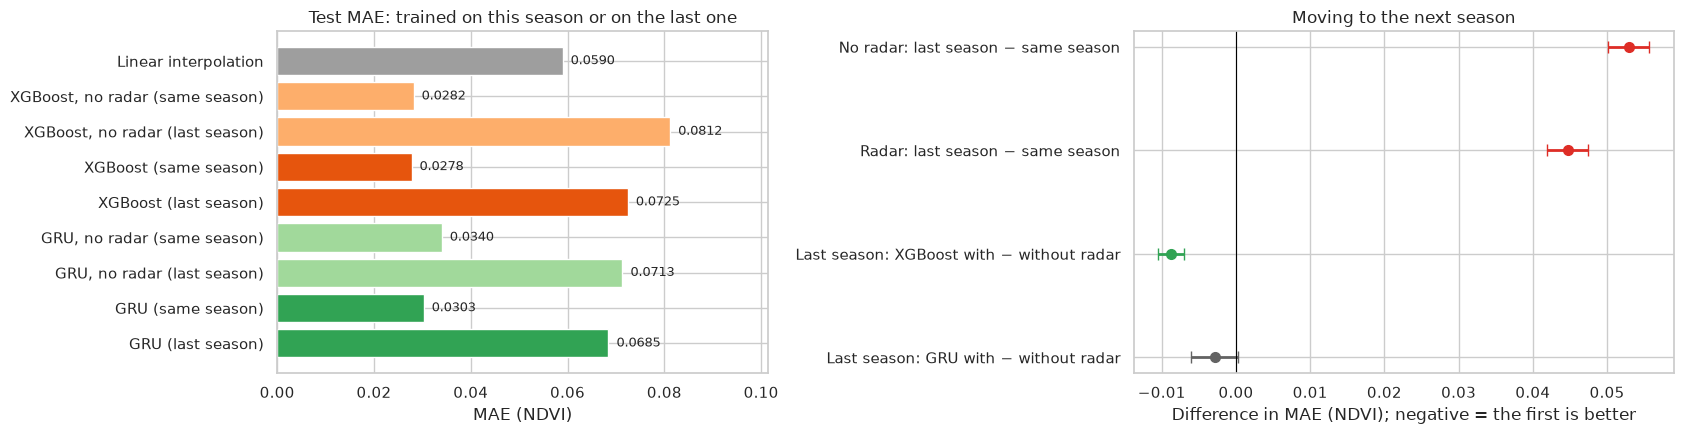

In [12]:
rows_prev = np.random.default_rng(SEED).permutation(len(grid_prev.parcel_ids))
stop_prev, fit_prev = rows_prev[: len(rows_prev) * 15 // 100], rows_prev[len(rows_prev) * 15 // 100 :]
stop_prev_hidden = gaps_for(grid_prev, stop_prev, seed=3)
train_prev = pd.concat([tabular(grid_prev, fit_prev, gaps_for(grid_prev, fit_prev, seed=200 + k)) for k in range(5)], ignore_index=True)
stop_prev_table = tabular(grid_prev, stop_prev, stop_prev_hidden)

prev_models = {
    "XGBoost, no radar": (fit_xgb(NO_RADAR_FEATURES, train_prev, stop_prev_table), NO_RADAR_FEATURES),
    "XGBoost": (fit_xgb(TABULAR_FEATURES, train_prev, stop_prev_table), TABULAR_FEATURES),
}
gru_prev = {r: gru_model("2023-24", grid_prev, fit_prev, stop_prev, stop_prev_hidden, use_radar=r) for r in (True, False)}
next_season = {}
for name, (model, features) in prev_models.items():
    next_season[name] = to_grid(test_table, model.predict(test_table[features]))
next_season["GRU, no radar"] = predict_gru(gru_prev[False][0], grid, test_hidden, gru_prev[False][1])
next_season["GRU"] = predict_gru(gru_prev[True][0], grid, test_hidden, gru_prev[True][1])

compare = errors(grid, test, test_hidden, {**{f"{k} (same season)": v for k, v in predictions.items()},
                                           **{f"{k} (last season)": v for k, v in next_season.items()}})
cols = [f"{m} ({w})" for m in ["XGBoost, no radar", "XGBoost", "GRU, no radar", "GRU"] for w in ("same season", "last season")]
fig, axes = plt.subplots(1, 2, figsize=(17, 4.5), gridspec_kw={"width_ratios": [1, 1.1]})
means = compare[["Linear interpolation (same season)"] + cols].mean().rename({"Linear interpolation (same season)": "Linear interpolation"})
mae_bars(means, "Test MAE: trained on this season or on the last one", ax=axes[0])
effect_plot(pd.DataFrame({
    "No radar: last season − same season": paired_difference(compare, "XGBoost, no radar (last season)", "XGBoost, no radar (same season)"),
    "Radar: last season − same season": paired_difference(compare, "XGBoost (last season)", "XGBoost (same season)"),
    "Last season: XGBoost with − without radar": paired_difference(compare, "XGBoost (last season)", "XGBoost, no radar (last season)"),
    "Last season: GRU with − without radar": paired_difference(compare, "GRU (last season)", "GRU, no radar (last season)"),
}).T, "Moving to the next season", ax=axes[1])
plt.tight_layout()
plt.savefig(FIGURES_DIR / "part2_next_season.png", dpi=130)

**What it shows**

- Trained on 2023–24, every model loses most of its gain. XGBoost without radar goes from 0.028 to 0.081:
  **worse than the straight line** (0.059), which it receives as an input.
- Radar now matters more: it cuts XGBoost's error by 0.009. The GRU, at 0.069, is the least affected.
- A model that does worse than its own input has learned something that is false in the new season.
  Section 12 finds what.

## 9. The next season, in real time

Past information only, one model per crop trained on 2023–24, applied to **all** 1,254 plots of 2024–25,
none of which were used for training.

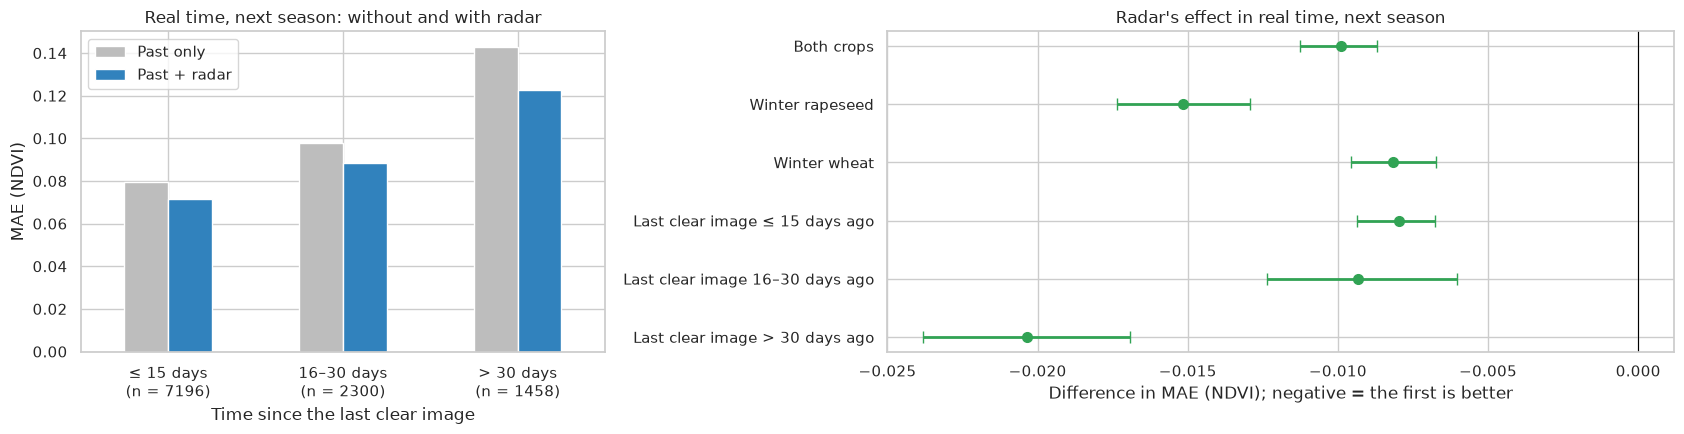

In [13]:
all_rows = np.arange(len(grid.parcel_ids))
all_hidden = gaps_for(grid, all_rows, seed=4)
all_table = tabular(grid, all_rows, all_hidden)
realtime_next = all_table[["parcel_id", "crop", "days_since_prev"]].copy()
realtime_next["without"] = per_crop(PAST_NO_RADAR, train_prev, stop_prev_table, all_table)
realtime_next["with"] = per_crop(PAST_RADAR, train_prev, stop_prev_table, all_table)
realtime_next["since"] = pd.cut(realtime_next["days_since_prev"], SINCE_BINS, labels=SINCE_LABELS)

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5), gridspec_kw={"width_ratios": [0.8, 1.2]})
by_since = realtime_next.groupby("since", observed=True)[["without", "with"]].mean().rename(columns={"without": "Past only", "with": "Past + radar"})
counts = realtime_next["since"].value_counts().reindex(by_since.index)
by_since.plot.bar(ax=axes[0], rot=0, color=["#bdbdbd", "#3182bd"])
axes[0].set_xticklabels([f"{s}\n(n = {n})" for s, n in counts.items()])
axes[0].set_xlabel("Time since the last clear image")
axes[0].set_ylabel("MAE (NDVI)")
axes[0].set_title("Real time, next season: without and with radar")
effect_plot(realtime_table(realtime_next), "Radar's effect in real time, next season", ax=axes[1])
plt.tight_layout()
plt.savefig(FIGURES_DIR / "part2_realtime_next_season.png", dpi=130)

**What it shows**

- In real time, radar cuts the error by 0.010 overall, by 0.015 for rapeseed, and by 0.020 when the last
  clear image is more than 30 days old.
- The errors are high, though (0.08 even after a recent clear image). Is that better than simply keeping the
  last clear value? Section 13 checks.

## 10. The next season, with real cloud patterns

The artificial gaps (one 30-day block plus single steps) are replaced by real ones: each 2024–25 plot gets
the cloud pattern of a random 2023–24 plot, whose spring was much wetter. A clear 2024–25 value is hidden
wherever that 2023–24 plot had no clear observation. The first and last observations stay visible.

Hidden: 31315 of 44014 clear observations (71%)


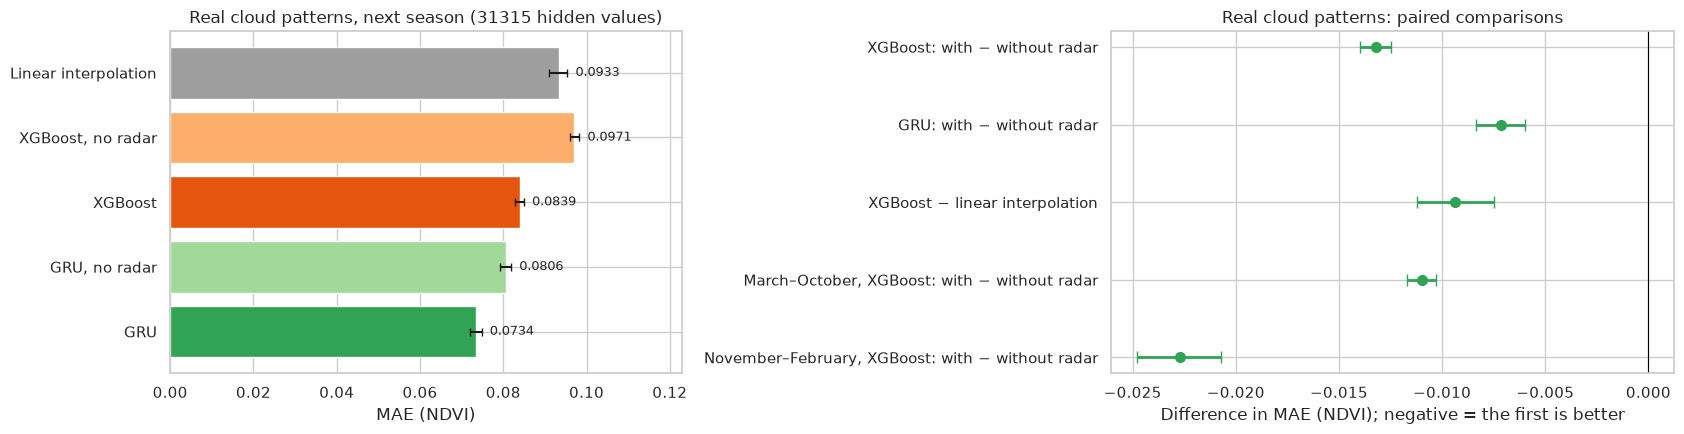

In [14]:
donors = np.random.default_rng(5).integers(0, len(grid_prev.parcel_ids), len(grid.parcel_ids))
real_hidden = grid.observed & ~grid_prev.observed[donors]
for p in all_rows:
    obs = np.flatnonzero(grid.observed[p])
    if len(obs):
        real_hidden[p, obs[0]] = real_hidden[p, obs[-1]] = False
real_visible = grid.observed & ~real_hidden
print(f"Hidden: {real_hidden.sum()} of {grid.observed.sum()} clear observations ({real_hidden.sum() / grid.observed.sum():.0%})")

real_table = tabular(grid, all_rows, real_hidden)
real_pred = {"Linear interpolation": linear_fill(grid.ndvi, real_visible)}
for name, (model, features) in prev_models.items():
    real_pred[name] = to_grid(real_table, model.predict(real_table[features]))
real_pred["GRU, no radar"] = predict_gru(gru_prev[False][0], grid, real_hidden, gru_prev[False][1])
real_pred["GRU"] = predict_gru(gru_prev[True][0], grid, real_hidden, gru_prev[True][1])
real_errors = errors(grid, all_rows, real_hidden, real_pred)
real_errors["period"] = np.where(real_errors["date"].dt.month.isin([11, 12, 1, 2]), "November–February", "March–October")

shown_real = ["Linear interpolation", "XGBoost, no radar", "XGBoost", "GRU, no radar", "GRU"]
fig, axes = plt.subplots(1, 2, figsize=(17, 4.5), gridspec_kw={"width_ratios": [1, 1.1]})
intervals = [bootstrap_mae(real_errors, m) for m in shown_real]
mae_bars(real_errors[shown_real].mean(), f"Real cloud patterns, next season ({len(real_errors)} hidden values)", intervals=intervals, ax=axes[0])
effect_plot(pd.DataFrame({
    "XGBoost: with − without radar": paired_difference(real_errors, "XGBoost", "XGBoost, no radar"),
    "GRU: with − without radar": paired_difference(real_errors, "GRU", "GRU, no radar"),
    "XGBoost − linear interpolation": paired_difference(real_errors, "XGBoost", "Linear interpolation"),
    "March–October, XGBoost: with − without radar": paired_difference(real_errors[real_errors.period == "March–October"], "XGBoost", "XGBoost, no radar"),
    "November–February, XGBoost: with − without radar": paired_difference(real_errors[real_errors.period == "November–February"], "XGBoost", "XGBoost, no radar"),
}).T, "Real cloud patterns: paired comparisons", ax=axes[1])
plt.tight_layout()
plt.savefig(FIGURES_DIR / "part2_real_clouds.png", dpi=130)

**What it shows**

- 71 % of the clear values are hidden: 2023–24 was much cloudier than 2024–25 (notebook 4), so most of these
  gaps last more than 45 days. This is a hard, but real, test.
- Only the GRU with radar clearly beats the straight line (0.073 against 0.093). XGBoost without radar is
  worse than it (0.097).
- Radar helps both models, most in winter (−0.023 for XGBoost).

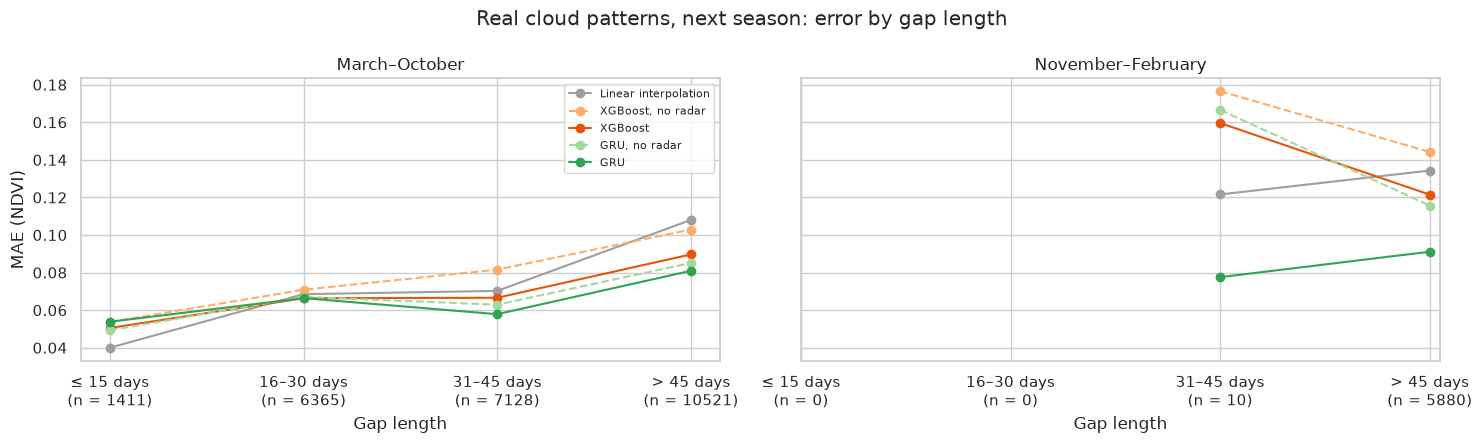

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, period in zip(axes, ["March–October", "November–February"]):
    d = real_errors[real_errors["period"] == period]
    gap_table = d.groupby("gap", observed=True)[shown_real].mean().reindex(GAP_LABELS)
    n = d["gap"].value_counts().reindex(GAP_LABELS).fillna(0).astype(int)
    for model in shown_real:
        color, style = STYLE[model]
        ax.plot(range(len(GAP_LABELS)), gap_table[model], marker="o", color=color, ls=style, label=model)
    ax.set_xticks(range(len(GAP_LABELS)), [f"{g}\n(n = {k})" for g, k in n.items()])
    ax.set_title(period)
    ax.set_xlabel("Gap length")
axes[0].set_ylabel("MAE (NDVI)")
axes[0].legend(fontsize=8)
fig.suptitle("Real cloud patterns, next season: error by gap length")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "part2_mae_by_gap.png", dpi=150)

**What it shows**

- From March to October, the straight line is best for gaps up to 15 days. The models win beyond 30 days,
  the GRU with radar most.
- In winter, almost every gap lasts more than 45 days. There, only the GRU with radar does clearly better
  than the line (0.091 against 0.134). The 31–45 day point rests on 10 values.

### Filled series under real clouds

Four 2024–25 plots with the longest real gaps, filled by the models trained on 2023–24. Pink: hidden by the
2023–24 cloud pattern (the truth is known, red circles). Grey: clouds of 2024–25 itself (no truth).


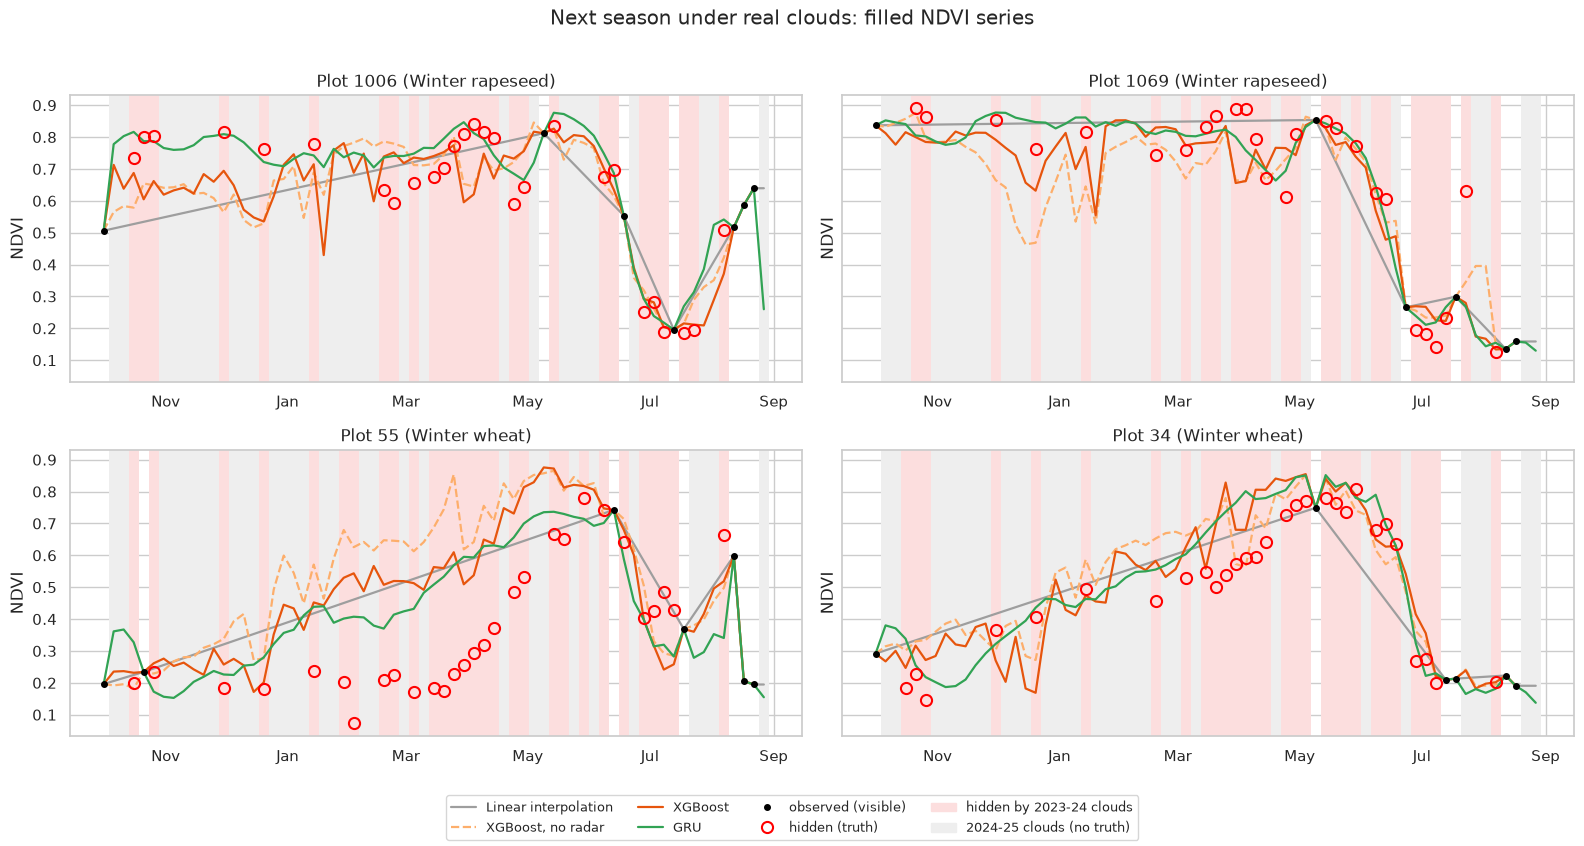

In [16]:
def plot_filled(filled, title, path):
    """The four example plots: visible values, hidden truth and each method's filled series."""
    filled = {name: np.where(real_visible, grid.ndvi, series) for name, series in filled.items()}
    half_step = pd.Timedelta(days=STEP_DAYS / 2)
    fig, axes = plt.subplots(2, 2, figsize=(16, 8.5), sharey=True)
    for ax, pid in zip(axes.flat, examples):
        p = row_of[pid]
        for t in np.flatnonzero(~grid.observed[p]):
            ax.axvspan(grid.dates[t] - half_step, grid.dates[t] + half_step, color="#eeeeee", lw=0)
        for t in np.flatnonzero(real_hidden[p]):
            ax.axvspan(grid.dates[t] - half_step, grid.dates[t] + half_step, color="#fcdede", lw=0)
        for name, series in filled.items():
            color, style = STYLE[name]
            ax.plot(grid.dates, series[p], color=color, ls=style, lw=1.6, label=name)
        visible, hidden = real_visible[p], real_hidden[p]
        ax.plot(grid.dates[visible], grid.ndvi[p, visible], "o", color="black", ms=4, label="observed (visible)")
        ax.plot(grid.dates[hidden], grid.ndvi[p, hidden], "o", mfc="none", mec="red", ms=8, mew=1.5, label="hidden (truth)")
        ax.set_title(f"Plot {pid} ({grid.crops[p]})")
        ax.set_ylabel("NDVI")
        ax.xaxis.set_major_formatter(MONTHS)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    handles += [plt.Rectangle((0, 0), 1, 1, color="#fcdede"), plt.Rectangle((0, 0), 1, 1, color="#eeeeee")]
    labels += ["hidden by 2023-24 clouds", "2024-25 clouds (no truth)"]
    fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=9)
    fig.suptitle(title)
    plt.tight_layout(rect=(0, 0.07, 1, 0.97))
    plt.savefig(FIGURES_DIR / path, dpi=130)


full_table = tabular(grid, all_rows, ~real_visible)  # every value the cloud pattern hides
filled = {"Linear interpolation": linear_fill(grid.ndvi, real_visible)}
for name, (model, features) in prev_models.items():
    filled[name] = to_grid(full_table, model.predict(full_table[features]))
filled["GRU"] = real_pred["GRU"]
longest = real_errors.groupby(["crop", "parcel_id"])["gap_days"].max()
examples = [pid for crop in CROPS for pid in longest[crop].nlargest(2).index]
plot_filled(filled, "Next season under real clouds: filled NDVI series", "part2_examples.png")

**What it shows**

- Pink bands everywhere: on these plots, the 2023–24 clouds hide most of the season. Grey bands are 2024–25's
  own clouds, where nothing can be checked. These four plots were picked for having the longest gaps.
- Plot 55 (wheat): from January to April, XGBoost without radar predicts 0.5 to 0.65 while the truth is
  around 0.2. That is the 2023–24 calendar, where wheat was green a month earlier. With radar, XGBoost is
  pulled halfway back; the GRU follows the truth more closely.
- Plot 1069 (rapeseed): XGBoost without radar invents dips in winter that no observation supports.

## 11. From the lab to real life

Each method's error in every setting, from the easiest (same season, artificial gaps) to the closest to
real use (last season's model, real clouds). Real-time results use past information only, with XGBoost per
crop.

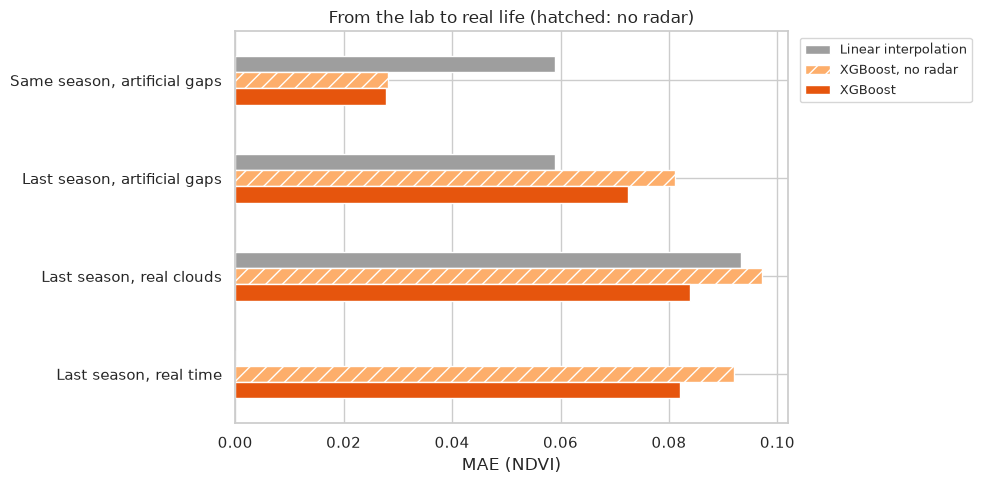

In [17]:
settings = {
    "Same season, artificial gaps": compare[["Linear interpolation (same season)", "XGBoost, no radar (same season)", "XGBoost (same season)"]].set_axis(["Linear interpolation", "XGBoost, no radar", "XGBoost"], axis=1),
    "Last season, artificial gaps": compare[["Linear interpolation (same season)", "XGBoost, no radar (last season)", "XGBoost (last season)"]].set_axis(["Linear interpolation", "XGBoost, no radar", "XGBoost"], axis=1),
    "Last season, real clouds": real_errors[["Linear interpolation", "XGBoost, no radar", "XGBoost"]],
}
summary = pd.DataFrame({name: d.mean() for name, d in settings.items()}).T
summary.loc["Last season, real time", ["XGBoost, no radar", "XGBoost"]] = realtime_next[["without", "with"]].mean().to_numpy()
ax = summary.plot.barh(figsize=(10, 5), color=[STYLE[m][0] for m in summary.columns])
for container, model in zip(ax.containers, summary.columns):
    if "no radar" in model:
        for bar in container:
            bar.set_hatch("//")
ax.invert_yaxis()
ax.set_xlabel("MAE (NDVI)")
ax.set_title("From the lab to real life (hatched: no radar)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "part2_lab_to_real_life.png", dpi=150)
results = summary.round(4)
results.to_csv(ROOT / "reports" / "part2_results.csv")

**What it shows**

- The lab result does not survive: XGBoost goes from 0.028 (same season, artificial gaps) to 0.084 (last
  season, real clouds). The straight line also gets worse, because real gaps are longer.
- In the last season, XGBoost without radar is worse than the straight line in both after-season tests.
- Radar is what keeps the learned models ahead in real life.
- "Learned models halve the error" was a lab artefact. Part C finds the cause and fixes it.

# Part C: what failed, and the fix

## 12. Why the last-season models failed

Section 8 ended on a contradiction: trained on 2023–24, XGBoost does worse than the straight line it gets as
an input. Section 3 gave a lead: after the straight line, XGBoost's most used input is the day of the year.
Notebook 4 showed that the same date is not the same crop stage from one year to the next. First, the two
seasons side by side.

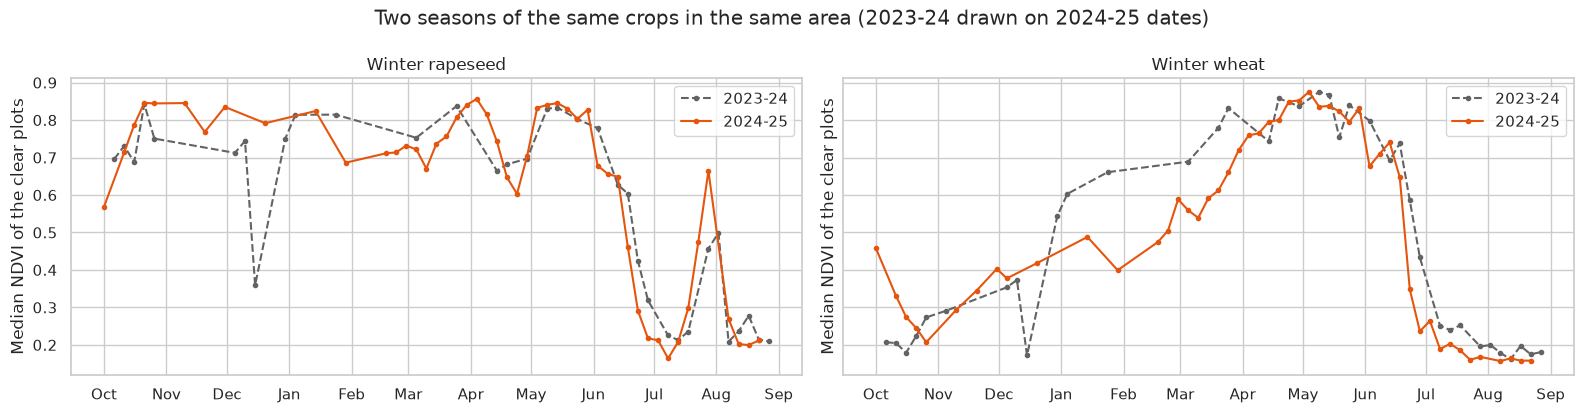

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2), sharey=True)
for ax, crop in zip(axes, CROPS):
    for g, season, color, style in [(grid_prev, "2023-24", "#636363", "--"), (grid, "2024-25", "#e6550d", "-")]:
        ndvi = pd.DataFrame(g.ndvi[g.crops == crop])
        median = ndvi.median().where(ndvi.count() >= 20).to_numpy()  # dates with at least 20 clear plots
        ok = ~np.isnan(median)
        ax.plot(grid.dates[ok], median[ok], ls=style, marker="o", ms=3, color=color, label=season)
    ax.set_title(crop)
    ax.set_ylabel("Median NDVI of the clear plots")
    ax.xaxis.set_major_formatter(MONTHS)
    ax.legend()
fig.suptitle("Two seasons of the same crops in the same area (2023-24 drawn on 2024-25 dates)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "part2_two_seasons.png", dpi=130)

**What it shows**

- From January to March, 2023–24 wheat is about a month ahead (0.69 against 0.50 in early March). Both
  seasons then peak together in May.
- A model that learned "early March: wheat at 0.7" from 2023–24 is wrong by 0.2 in 2025.
- Why the date looked so useful within one season: all plots of the area share the same weather, so the date
  tells the model this year's regional curve. Artificial gaps hide one plot at a time, and the training
  plots stay visible on those same dates, so the model learns the regional curve from them. Real clouds cover
  the whole area at once, and a new season has a new curve.

The test: the same XGBoost models, trained with and without the two date features.

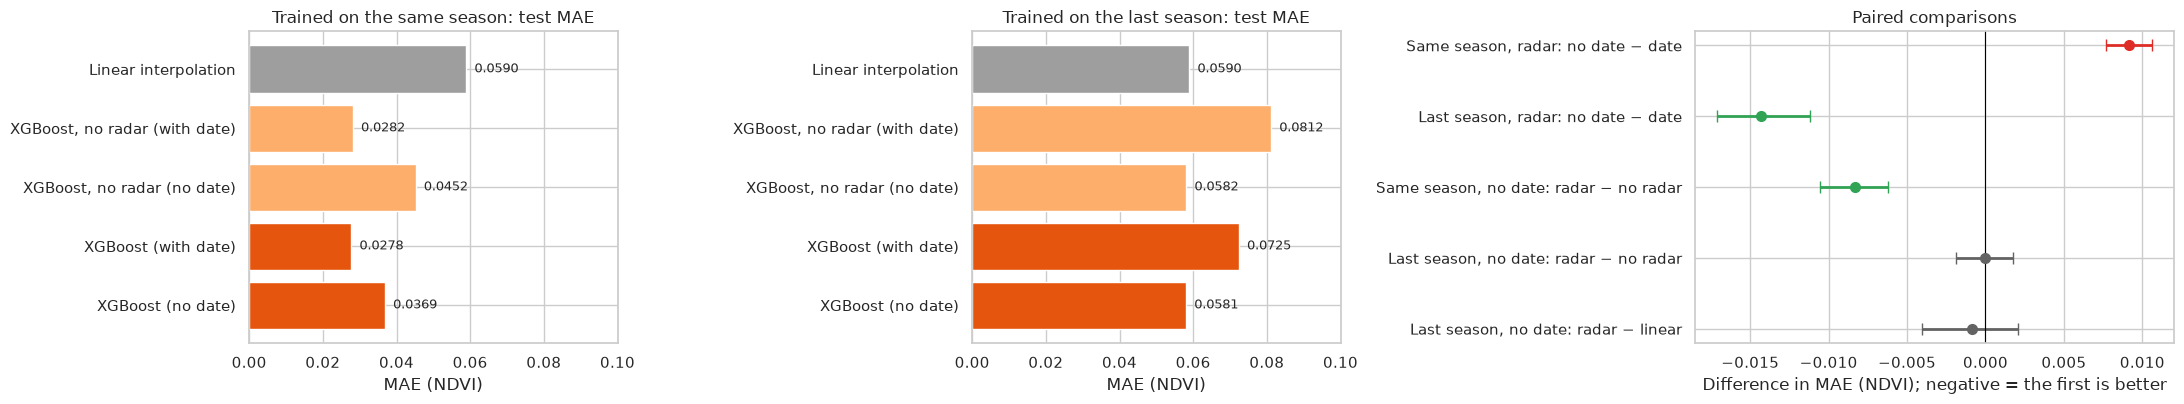

In [19]:
date_errors, date_models = {}, {}
for setting, (tr, va) in {"Same season": (train_table, val_table), "Last season": (train_prev, stop_prev_table)}.items():
    err = test_table[["parcel_id", "crop", "gap_days"]].copy()
    err["Linear interpolation"] = np.abs(test_table["linear"] - test_table["target"])
    for name, features in [("XGBoost, no radar", NO_RADAR_FEATURES), ("XGBoost", TABULAR_FEATURES)]:
        for label, f in [("with date", features), ("no date", without_date(features))]:
            model = fit_xgb(f, tr, va)
            date_models[(setting, name, label)] = (model, f)
            err[f"{name} ({label})"] = np.abs(model.predict(test_table[f]) - test_table["target"])
    date_errors[setting] = err

methods = ["Linear interpolation", "XGBoost, no radar (with date)", "XGBoost, no radar (no date)", "XGBoost (with date)", "XGBoost (no date)"]
fig, axes = plt.subplots(1, 3, figsize=(22, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.3]})
for ax, (setting, err) in zip(axes, date_errors.items()):
    mae_bars(err[methods].mean(), f"Trained on the {setting.lower()}: test MAE", ax=ax)
    ax.set_xlim(0, 0.1)
same, last = date_errors["Same season"], date_errors["Last season"]
effect_plot(pd.DataFrame({
    "Same season, radar: no date − date": paired_difference(same, "XGBoost (no date)", "XGBoost (with date)"),
    "Last season, radar: no date − date": paired_difference(last, "XGBoost (no date)", "XGBoost (with date)"),
    "Same season, no date: radar − no radar": paired_difference(same, "XGBoost (no date)", "XGBoost, no radar (no date)"),
    "Last season, no date: radar − no radar": paired_difference(last, "XGBoost (no date)", "XGBoost, no radar (no date)"),
    "Last season, no date: radar − linear": paired_difference(last, "XGBoost (no date)", "Linear interpolation"),
}).T, "Paired comparisons", ax=axes[2])
plt.tight_layout()
plt.savefig(FIGURES_DIR / "part2_date_experiment.png", dpi=130)

**What it shows**

- Within one season, the date is worth a lot: without it, XGBoost goes from 0.028 to 0.037 (with radar) and
  0.045 (without). That gain is 2024–25's regional curve, which the model only knows because it was trained
  on the same season.
- Trained on the last season, the date does harm: without it, XGBoost with radar goes from 0.073 to 0.058,
  no longer worse than the straight line (0.059).
- Without the date, radar becomes the model's way to know the crop's stage: within one season, it now cuts the
  error by 0.008 (20 %), where it added nothing with the date.
- **Diagnosis:** the models learned the calendar of the season they were trained on. "Halves the error"
  measured that memory, not a skill that carries over to a new year.

## 13. The fix: models without the date

The real-life tests of sections 9 and 10 again (trained on 2023–24, applied to 2024–25), with the date
removed. XGBoost comes from section 12; the two GRUs are trained again without their day-of-year inputs.

GRU 2023-24, with radar, no date: best validation MAE 0.0467
GRU 2023-24, without radar, no date: best validation MAE 0.0502


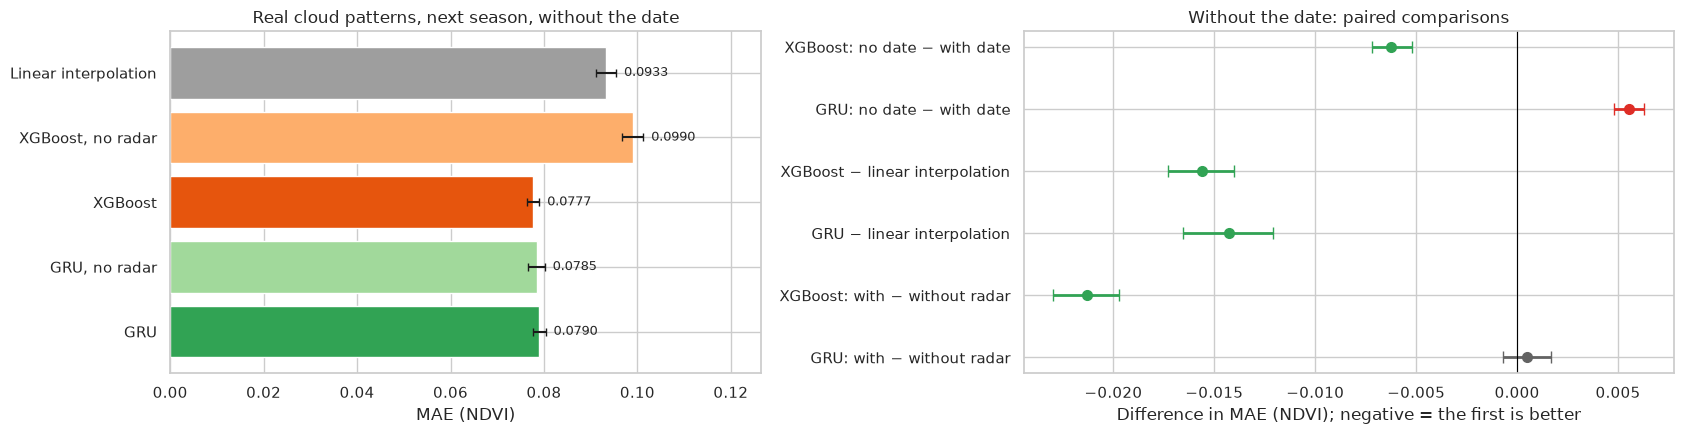

In [20]:
gru_no_date = {r: gru_model("2023-24", grid_prev, fit_prev, stop_prev, stop_prev_hidden, use_radar=r, use_date=False) for r in (True, False)}
fixed = {"Linear interpolation": real_pred["Linear interpolation"]}
for name in ["XGBoost, no radar", "XGBoost"]:
    model, f = date_models[("Last season", name, "no date")]
    fixed[name] = to_grid(real_table, model.predict(real_table[f]))
fixed["GRU, no radar"] = predict_gru(gru_no_date[False][0], grid, real_hidden, gru_no_date[False][1])
fixed["GRU"] = predict_gru(gru_no_date[True][0], grid, real_hidden, gru_no_date[True][1])
fixed_errors = errors(grid, all_rows, real_hidden, fixed)
fixed_errors["period"] = real_errors["period"].to_numpy()
for name in ["XGBoost", "GRU"]:  # the same hidden values, predicted by the models with the date
    fixed_errors[f"{name} (with date)"] = real_errors[name].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5), gridspec_kw={"width_ratios": [1, 1.1]})
intervals = [bootstrap_mae(fixed_errors, m) for m in shown_real]
mae_bars(fixed_errors[shown_real].mean(), "Real cloud patterns, next season, without the date", intervals=intervals, ax=axes[0])
effect_plot(pd.DataFrame({
    "XGBoost: no date − with date": paired_difference(fixed_errors, "XGBoost", "XGBoost (with date)"),
    "GRU: no date − with date": paired_difference(fixed_errors, "GRU", "GRU (with date)"),
    "XGBoost − linear interpolation": paired_difference(fixed_errors, "XGBoost", "Linear interpolation"),
    "GRU − linear interpolation": paired_difference(fixed_errors, "GRU", "Linear interpolation"),
    "XGBoost: with − without radar": paired_difference(fixed_errors, "XGBoost", "XGBoost, no radar"),
    "GRU: with − without radar": paired_difference(fixed_errors, "GRU", "GRU, no radar"),
}).T, "Without the date: paired comparisons", ax=axes[1])
plt.tight_layout()
plt.savefig(FIGURES_DIR / "part2_real_clouds_no_date.png", dpi=130)

**What it shows**

- Under real clouds, XGBoost with radar improves from 0.084 to 0.078 without the date: 17 % better than the
  straight line (0.093), against 10 % before.
- Radar is what makes it work: without radar, XGBoost is at 0.099, worse than the line.
- The GRU goes the other way: 0.073 with the date, 0.079 without. It reads the whole season, so it can set the
  date against the plot's own observations instead of looking up a regional value. For the GRU, the date
  helps, and the GRU with the date remains the best model in this test.
- Without the date, the GRU gains nothing from radar.

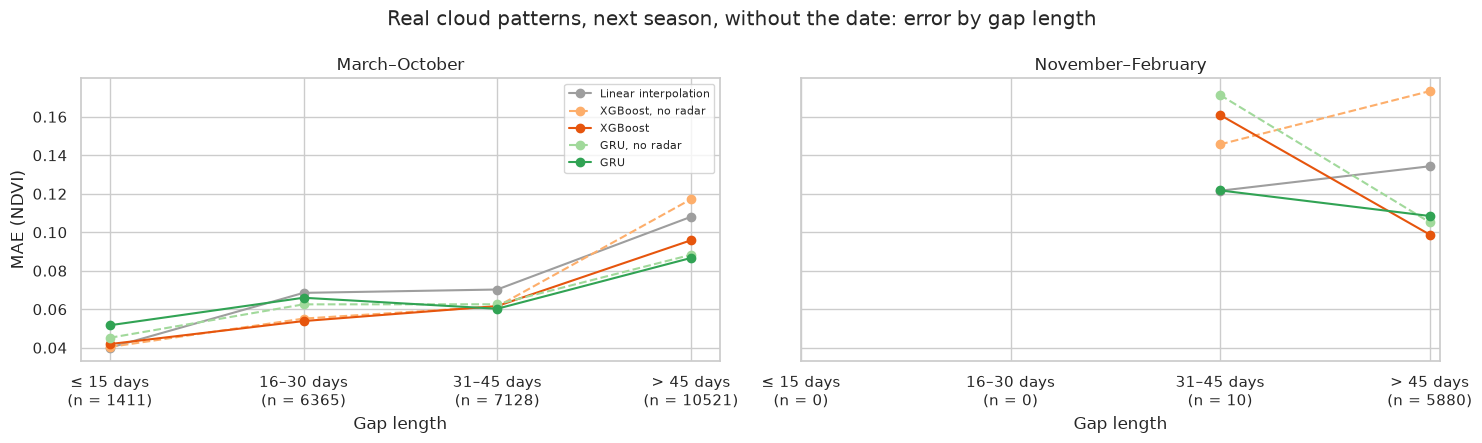

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, period in zip(axes, ["March–October", "November–February"]):
    d = fixed_errors[fixed_errors["period"] == period]
    gap_table = d.groupby("gap", observed=True)[shown_real].mean().reindex(GAP_LABELS)
    n = d["gap"].value_counts().reindex(GAP_LABELS).fillna(0).astype(int)
    for model in shown_real:
        color, style = STYLE[model]
        ax.plot(range(len(GAP_LABELS)), gap_table[model], marker="o", color=color, ls=style, label=model)
    ax.set_xticks(range(len(GAP_LABELS)), [f"{g}\n(n = {k})" for g, k in n.items()])
    ax.set_title(period)
    ax.set_xlabel("Gap length")
axes[0].set_ylabel("MAE (NDVI)")
axes[0].legend(fontsize=8)
fig.suptitle("Real cloud patterns, next season, without the date: error by gap length")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "part2_mae_by_gap_no_date.png", dpi=150)

**What it shows**

- From March to October, XGBoost without the date now matches the straight line on short gaps (0.042 against
  0.040; with the date it was at 0.051) and beats it from 16 days on. The GRU stays behind on short gaps (0.052).
- In winter, where almost every gap lasts more than 45 days, XGBoost with radar does best (0.099 against 0.134
  for the line). XGBoost without radar is the worst (0.173).

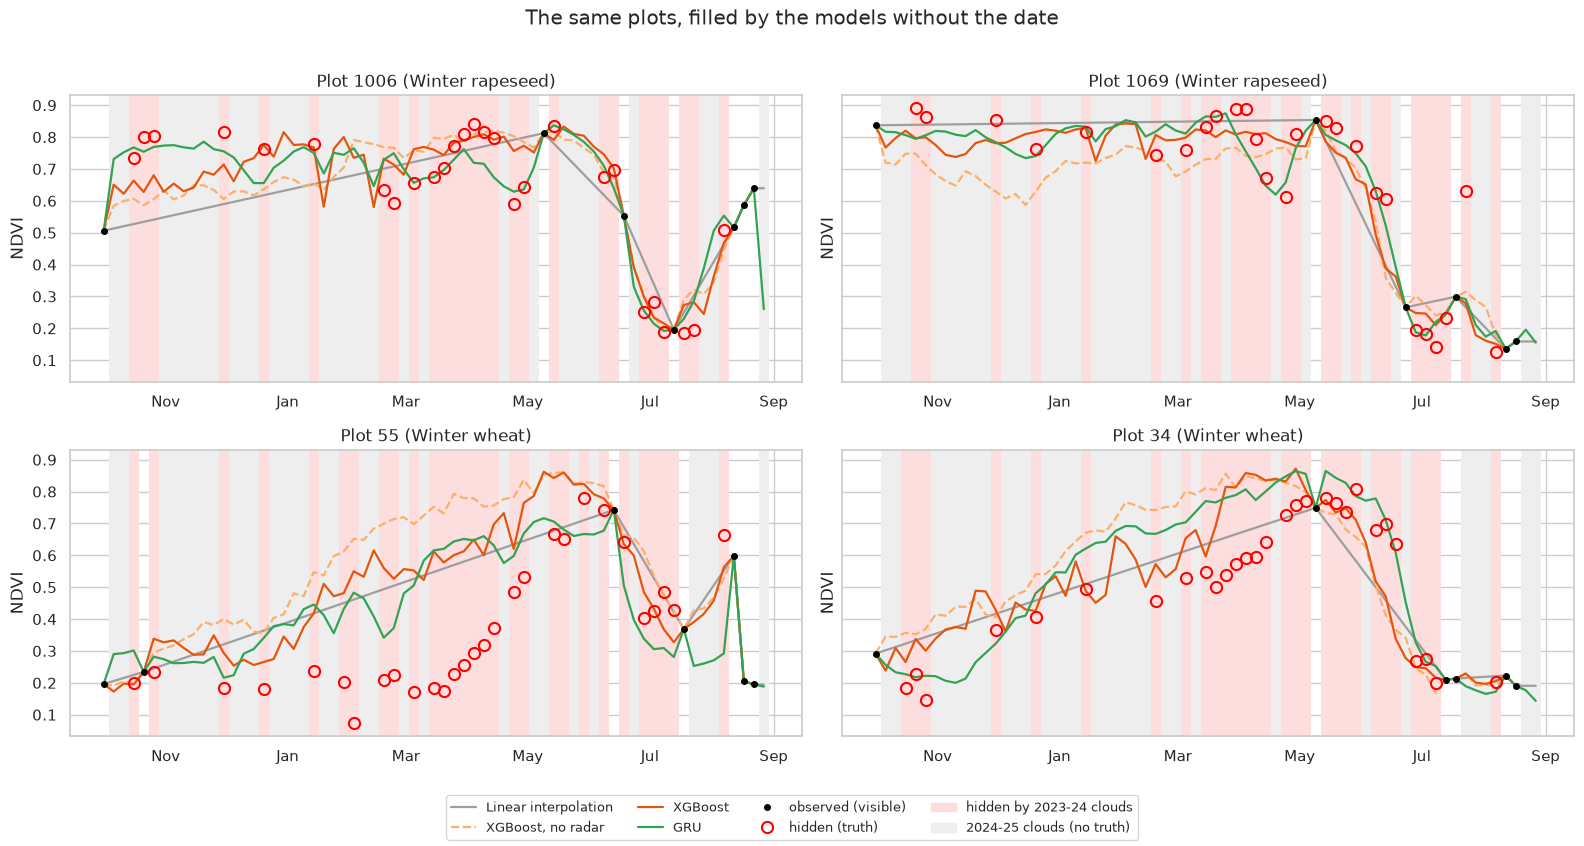

In [22]:
filled_fixed = {"Linear interpolation": filled["Linear interpolation"]}
for name in ["XGBoost, no radar", "XGBoost"]:
    model, f = date_models[("Last season", name, "no date")]
    filled_fixed[name] = to_grid(full_table, model.predict(full_table[f]))
filled_fixed["GRU"] = fixed["GRU"]
plot_filled(filled_fixed, "The same plots, filled by the models without the date", "part2_examples_no_date.png")

**What it shows**

- Plot 1069 (rapeseed): with radar, XGBoost's invented winter dips are gone.
- Plot 55 (wheat): XGBoost with radar no longer climbs to 0.65 in February, but it still sits above the truth.
  This plot stayed near 0.2 until April, far below both seasons' median. Without radar, XGBoost still drifts
  up.
- The fix removes the worst errors, not all of them.

### Real time without the date

The test of section 9 again, plus the simplest real-time answer: keep the last clear value.

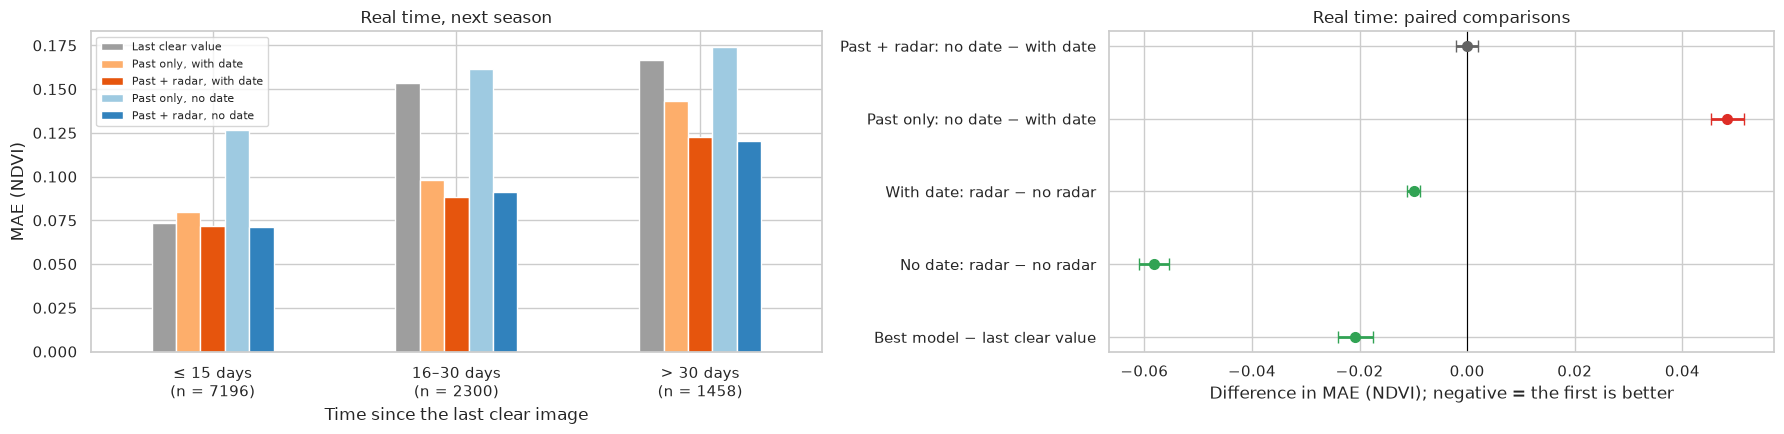

In [23]:
realtime_fixed = all_table[["parcel_id", "crop", "days_since_prev"]].copy()
realtime_fixed["Last clear value"] = np.abs(all_table["prev_ndvi"] - all_table["target"])
realtime_fixed["Past only, with date"] = realtime_next["without"]
realtime_fixed["Past + radar, with date"] = realtime_next["with"]
realtime_fixed["Past only, no date"] = per_crop(without_date(PAST_NO_RADAR), train_prev, stop_prev_table, all_table)
realtime_fixed["Past + radar, no date"] = per_crop(without_date(PAST_RADAR), train_prev, stop_prev_table, all_table)
realtime_fixed["since"] = pd.cut(realtime_fixed["days_since_prev"], SINCE_BINS, labels=SINCE_LABELS)

rt_methods = ["Last clear value", "Past only, with date", "Past + radar, with date", "Past only, no date", "Past + radar, no date"]
fig, axes = plt.subplots(1, 2, figsize=(18, 4.5), gridspec_kw={"width_ratios": [1.1, 1]})
by_since = realtime_fixed.groupby("since", observed=True)[rt_methods].mean()
counts = realtime_fixed["since"].value_counts().reindex(by_since.index)
by_since.plot.bar(ax=axes[0], rot=0, color=["#9e9e9e", "#fdae6b", "#e6550d", "#9ecae1", "#3182bd"])
axes[0].set_xticklabels([f"{s}\n(n = {n})" for s, n in counts.items()])
axes[0].set_xlabel("Time since the last clear image")
axes[0].set_ylabel("MAE (NDVI)")
axes[0].set_title("Real time, next season")
axes[0].legend(fontsize=8)
effect_plot(pd.DataFrame({
    "Past + radar: no date − with date": paired_difference(realtime_fixed, "Past + radar, no date", "Past + radar, with date"),
    "Past only: no date − with date": paired_difference(realtime_fixed, "Past only, no date", "Past only, with date"),
    "With date: radar − no radar": paired_difference(realtime_fixed, "Past + radar, with date", "Past only, with date"),
    "No date: radar − no radar": paired_difference(realtime_fixed, "Past + radar, no date", "Past only, no date"),
    "Best model − last clear value": paired_difference(realtime_fixed, "Past + radar, no date", "Last clear value"),
}).T, "Real time: paired comparisons", ax=axes[1])
plt.tight_layout()
plt.savefig(FIGURES_DIR / "part2_realtime_no_date.png", dpi=130)

**What it shows**

- Keeping the last clear value is hard to beat right after a clear image (0.073 under 15 days, as good as any
  model), and poor after weeks of clouds (0.15 to 0.17).
- With radar, the date no longer matters (0.082 with or without it): radar tells the model where the crop is.
- Without radar, the date is essential: removing it raises the error from 0.092 to 0.140, worse than keeping
  the last clear value (0.103).
- The best real-time model (past + radar) is 20 % better than the last clear value (0.082 against 0.103), and
  all of that gain comes after gaps longer than 15 days.

## 14. From the lab to real life, after the fix

Section 11 again (left), next to the same settings without the date (right). In real time, the grey bar is
the last clear value.

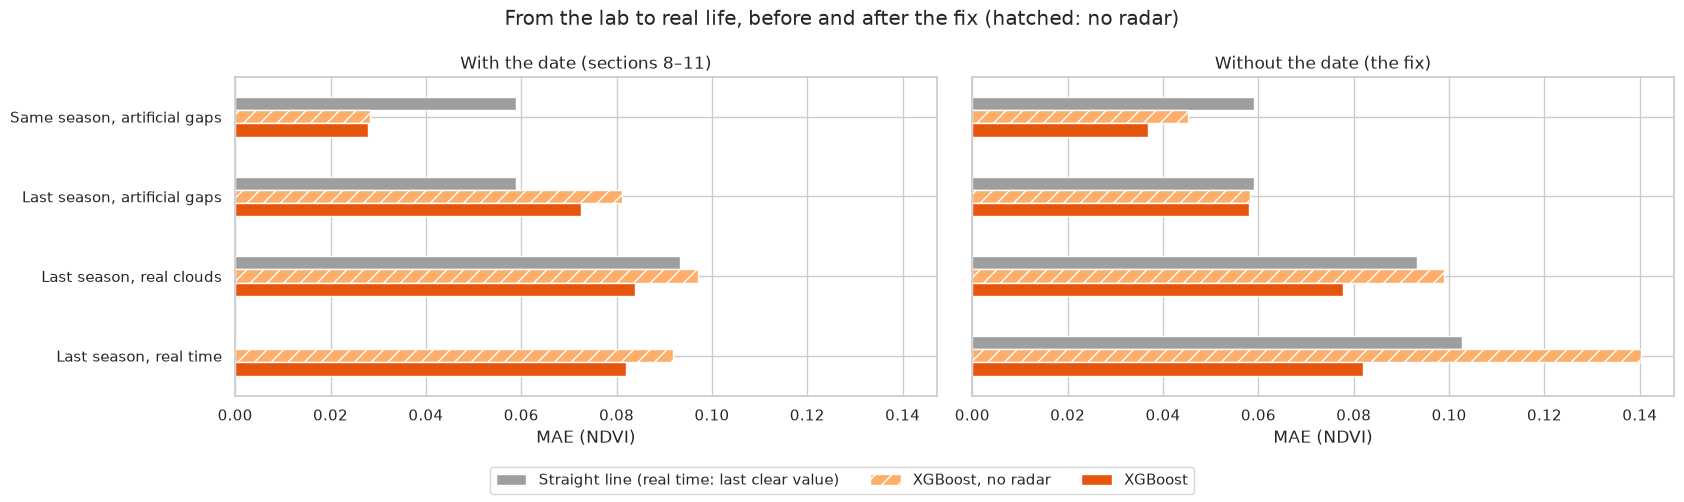

In [24]:
columns = ["Linear interpolation", "XGBoost, no radar", "XGBoost"]
fixed_summary = pd.DataFrame({
    "Same season, artificial gaps": date_errors["Same season"][["Linear interpolation", "XGBoost, no radar (no date)", "XGBoost (no date)"]].mean().set_axis(columns),
    "Last season, artificial gaps": date_errors["Last season"][["Linear interpolation", "XGBoost, no radar (no date)", "XGBoost (no date)"]].mean().set_axis(columns),
    "Last season, real clouds": fixed_errors[columns].mean(),
}).T
fixed_summary.loc["Last season, real time", columns] = realtime_fixed[["Last clear value", "Past only, no date", "Past + radar, no date"]].mean().to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(17, 5), sharey=True, sharex=True)
for ax, (title, table) in zip(axes, [("With the date (sections 8–11)", summary), ("Without the date (the fix)", fixed_summary)]):
    table.plot.barh(ax=ax, color=[STYLE[m][0] for m in table.columns], legend=False)
    for container, model in zip(ax.containers, table.columns):
        if "no radar" in model:
            for bar in container:
                bar.set_hatch("//")
    ax.set_xlabel("MAE (NDVI)")
    ax.set_title(title)
axes[0].invert_yaxis()
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, ["Straight line (real time: last clear value)", "XGBoost, no radar", "XGBoost"], loc="lower center", ncol=3)
fig.suptitle("From the lab to real life, before and after the fix (hatched: no radar)")
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.savefig(FIGURES_DIR / "part2_lab_to_real_life_fixed.png", dpi=150)
fixed_summary.round(4).to_csv(ROOT / "reports" / "part2_results_no_date.csv")

**What it shows**

- The lab score is less flattering without the date (0.037 instead of 0.028), and closer to what happens in a
  new season.
- In every real-life setting, XGBoost with radar is now at least as good as the simple answer: equal to the
  straight line on artificial gaps, 17 % better under real clouds, and 20 % better than the last clear value
  in real time.
- Without radar, no XGBoost model reliably beats the simple answer in a new season.

## 15. What affected these results

| Factor | Effect |
|---|---|
| Only two seasons | One test of the change between years; another pair of years could differ |
| 2023–24 much cloudier than 2024–25 | Fewer clear spring values to learn from; the real-cloud test hides 71 % of the values |
| One area east of Reims, two crops | The results may not hold for other regions or crops |
| Artificial gaps hide one plot at a time | Same-season scores are optimistic: the regional curve leaks from the other plots (section 12) |
| Truth only exists on clear dates | The cloudiest periods, where filling matters most, are scored least |
| One training seed per GRU | GRU differences of a few thousandths may be noise |

## 16. Conclusion

| Hypothesis (notebook 4) | Verdict |
|---|---|
| G1: within one season, learned models halve the error | Confirmed (−53 %), but mostly through the date; −37 % without it |
| G2: within one season, radar adds little after the season | Confirmed: about 5 % |
| G3: trained on 2023–24, the model without radar loses on 2024–25 | Confirmed, and worse than guessed: it falls below the straight line |
| G4: across seasons, radar helps more | Confirmed: from nothing to −0.009 (artificial gaps) and −0.013 (real clouds) |
| G5: in real time, radar's help grows with the time since the last clear image | Confirmed: −0.008, −0.009, then −0.020 beyond 30 days |
| G6: under real clouds, radar models keep their advantage | Confirmed with the date; without it, only XGBoost keeps a radar advantage |

- **What failed:** testing within one season. The models learned that season's regional calendar through the
  date, and the calendar moved the next year (wheat a month ahead in 2023–24).
- **The fix:** remove the date wherever radar can replace it. Radar sees each plot's actual stage, whatever the
  calendar.
- **What holds in real life** (trained on last season, applied to this one): XGBoost with radar and without the
  date is 17 % better than the straight line after the season, under real clouds, and 20 % better than the
  last clear value in real time. The GRU with the date reaches 21 %, but it needs PyTorch.
- **Radar's value:** small within one season, essential across seasons. Without radar, no XGBoost model reliably
  beats the simple answers.
- **For the API:** the served models drop the date, except the real-time model without radar, which needs it
  (section 13).
- **Next steps:** replace the date with a clock that follows the weather, such as growing degree days from
  ERA5 temperatures, so that a model knows the crop's stage in a mild or a cold year; train on more past
  seasons; serve the GRU through ONNX.